# Clasificador Bayesiano para el dataset *digits* de scikit-learn

**Tema:** Clasificadores Bayesianos (Naive Bayes)

**Integrantes:** Alan Garcia - Alejandra Restrepo - Gabriel caicedo

Los pasos que seguí fueron:
1. Cargar el dataset y explorarlo un poco.
2. Separar 80 % de los datos para entrenamiento y 20 % para prueba.
3. Revisar cómo se distribuyen los valores de los píxeles.
4. Comparar varias versiones de Naive Bayes con validación cruzada K-fold ($K=4$).
5. Escoger el mejor clasificador y explicar por qué.
6. Aplicar suavizado de Laplace y analizar el efecto de $\alpha$.
7. Probar el modelo final con los datos de prueba.

## 1. Un poco de teoría

Antes de empezar repasé la idea del clasificador bayesiano. Lo que hace es calcular, para cada clase, qué tan probable es que la muestra $\mathbf{x}$ pertenezca a ella, usando el teorema de Bayes, y se queda con la clase más probable:

$$
P(y \mid \mathbf{x}) = \frac{P(\mathbf{x} \mid y)\,P(y)}{P(\mathbf{x})}
\quad\Rightarrow\quad
\hat{y} = \arg\max_{y} \; P(y)\,P(\mathbf{x} \mid y)
$$

El denominador $P(\mathbf{x})$ es igual para todas las clases, así que para decidir no hace falta calcularlo.

Se llama **Naive** ("ingenuo") porque supone que todas las características son independientes entre sí si ya se conoce la clase. Así la probabilidad conjunta se vuelve un producto sencillo:

$$
P(\mathbf{x} \mid y) = \prod_{j=1}^{n} P(x_j \mid y)
$$

Ese supuesto casi nunca se cumple del todo (en una imagen, los píxeles vecinos sí están relacionados), pero en la práctica el método funciona bastante bien.

Lo importante es que $P(x_j \mid y)$ se puede modelar con distintas distribuciones según el tipo de dato, y de ahí salen las versiones que trae scikit-learn:

| Variante | Qué supone de cada $x_j$ | Para qué datos sirve |
|---|---|---|
| `GaussianNB` | Continua y con distribución normal $\mathcal{N}(\mu_{jy}, \sigma^2_{jy})$ | Medidas reales (altura, temperatura) |
| `MultinomialNB` | Conteos enteros $\geq 0$ (distribución multinomial) | Frecuencias, conteo de palabras o eventos |
| `BernoulliNB` | Binaria (0 o 1) | Presencia o ausencia de algo |
| `CategoricalNB` | Categórica (cada valor es una categoría) | Variables discretas sin orden |
| `ComplementNB` | Multinomial, pero estimada con el "complemento" de cada clase | Texto con clases desbalanceadas |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.naive_bayes import (GaussianNB, MultinomialNB, BernoulliNB,
                                 CategoricalNB, ComplementNB)
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report,
                             ConfusionMatrixDisplay)

import warnings
from sklearn.exceptions import UndefinedMetricWarning
# Con alfa extremos algunas clases nunca se predicen y la precisión queda indefinida (se toma 0)
warnings.filterwarnings("ignore", category=UndefinedMetricWarning)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 2. Carga y exploración del dataset

El dataset *digits* tiene **1797 imágenes** de dígitos de **8×8 píxeles**, o sea **64 características** por imagen. Leyendo la documentación de scikit-learn encontré un detalle que después fue clave: las imágenes originales eran de 32×32, se dividieron en bloques de 4×4 y **en cada bloque se contó cuántos píxeles estaban encendidos**. Por eso cada característica es un número entero entre **0 y 16**.

In [2]:
digits = load_digits()
X, y = digits.data, digits.target

print("Forma de X:", X.shape)
print("Forma de y:", y.shape)
print("Clases:", np.unique(y))
print("Valores distintos en X:", np.unique(X).astype(int))
print("\nMuestras por clase:")
print(pd.Series(y).value_counts().sort_index().to_frame("n").T)

Forma de X: (1797, 64)
Forma de y: (1797,)
Clases: [0 1 2 3 4 5 6 7 8 9]
Valores distintos en X: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16]

Muestras por clase:
     0    1    2    3    4    5    6    7    8    9
n  178  182  177  183  181  182  181  179  174  180


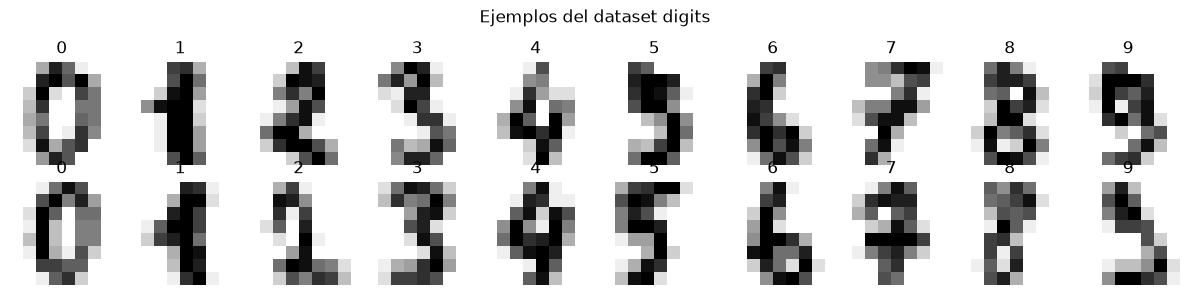

In [3]:
fig, axes = plt.subplots(2, 10, figsize=(12, 3))
for ax, img, label in zip(axes.ravel(), digits.images, digits.target):
    ax.imshow(img, cmap="gray_r")
    ax.set_title(label)
    ax.axis("off")
plt.suptitle("Ejemplos del dataset digits")
plt.tight_layout()
plt.show()

Viendo los conteos por clase, todas tienen alrededor de 180 imágenes, así que el dataset está **balanceado**. Eso significa que la *accuracy* sí es una buena métrica aquí, pero de todas formas también voy a medir precisión, *recall* y F1 (promedio *macro*) para tener una visión más completa.

## 3. División del dataset: 80 % entrenamiento / 20 % prueba

Separé los datos con `train_test_split`, usando `stratify=y` para que en los dos conjuntos quede más o menos la misma proporción de cada dígito. Puse `random_state=42` para que los resultados se puedan repetir.

Algo que tuve en cuenta: **el conjunto de prueba no lo uso hasta el final**. Todas las comparaciones entre modelos y la elección de $\alpha$ las hago con validación cruzada dentro del conjunto de entrenamiento, para no "hacer trampa" ajustando el modelo a los datos de prueba.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print(f"Entrenamiento: {X_train.shape[0]} muestras ({X_train.shape[0]/len(X):.0%})")
print(f"Prueba:        {X_test.shape[0]} muestras ({X_test.shape[0]/len(X):.0%})")

Entrenamiento: 1437 muestras (80%)
Prueba:        360 muestras (20%)


## 4. ¿Qué distribución siguen los datos?

Para saber qué versión de Naive Bayes usar, primero quise ver cómo son los valores de los píxeles. Hice un histograma de todos los valores y comparé un mismo píxel en dos clases distintas.

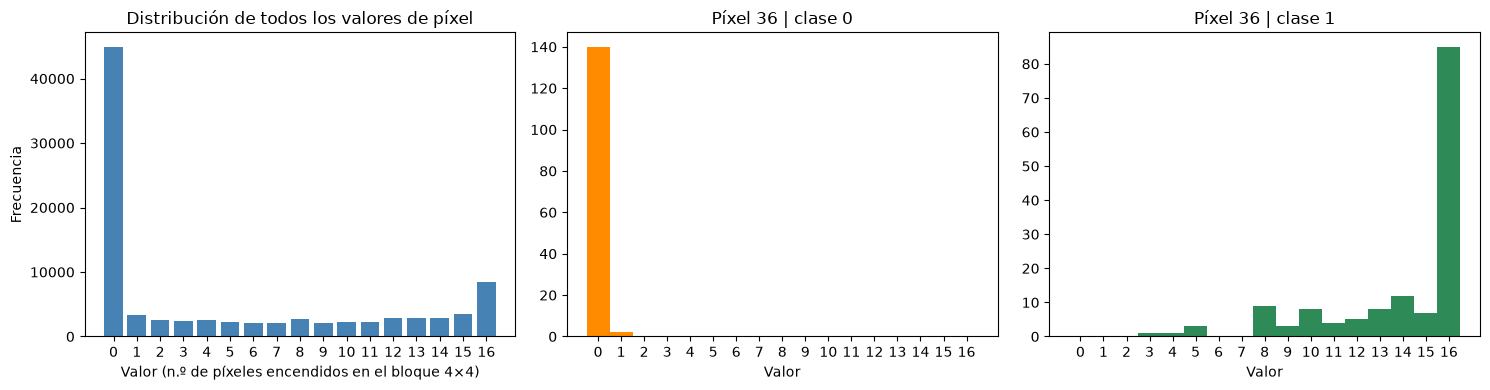

Porcentaje de ceros en X_train: 48.9%
Porcentaje de valores = 16:     9.1%


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# (a) Histograma global de los valores de los píxeles
valores, conteos = np.unique(X_train, return_counts=True)
axes[0].bar(valores, conteos, color="steelblue")
axes[0].set_title("Distribución de todos los valores de píxel")
axes[0].set_xlabel("Valor (n.º de píxeles encendidos en el bloque 4×4)")
axes[0].set_ylabel("Frecuencia")
axes[0].set_xticks(range(17))

# (b) Distribución de un píxel central para la clase 0
pix = 36  # fila 4, columna 4
axes[1].hist(X_train[y_train == 0, pix], bins=np.arange(18) - 0.5, color="darkorange")
axes[1].set_title(f"Píxel {pix} | clase 0")
axes[1].set_xlabel("Valor"); axes[1].set_xticks(range(17))

# (c) Distribución del mismo píxel para la clase 1
axes[2].hist(X_train[y_train == 1, pix], bins=np.arange(18) - 0.5, color="seagreen")
axes[2].set_title(f"Píxel {pix} | clase 1")
axes[2].set_xlabel("Valor"); axes[2].set_xticks(range(17))

plt.tight_layout()
plt.show()

print(f"Porcentaje de ceros en X_train: {(X_train == 0).mean():.1%}")
print(f"Porcentaje de valores = 16:     {(X_train == 16).mean():.1%}")

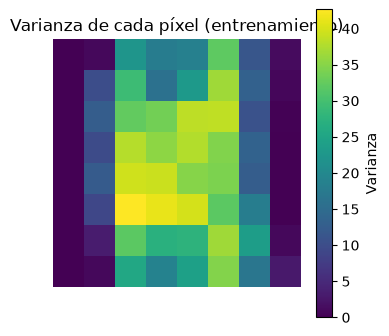

Píxeles con varianza 0 en entrenamiento: 3


In [6]:
# Varianza por píxel: algunos píxeles del borde son siempre 0 (varianza nula)
var_pixeles = X_train.var(axis=0).reshape(8, 8)
plt.figure(figsize=(4, 4))
plt.imshow(var_pixeles, cmap="viridis")
plt.colorbar(label="Varianza")
plt.title("Varianza de cada píxel (entrenamiento)")
plt.axis("off")
plt.show()

print("Píxeles con varianza 0 en entrenamiento:", int((var_pixeles == 0).sum()))

**Lo que noté:**

- Todos los valores son **enteros y no negativos** (de 0 a 16), así que los datos no son continuos.
- La distribución está **muy cargada hacia el 0**: casi la mitad de los valores (48.9 %) son ceros, y hay otro pico en 16. No se parece en nada a una campana, así que el supuesto de normalidad de `GaussianNB` no se cumple.
- Hay píxeles del borde que valen 0 en todas las imágenes (varianza 0). Para una gaussiana eso es un problema, porque tendría $\sigma^2 = 0$.
- Lo más importante: cada valor es literalmente un **conteo** (cuántos de los 16 píxeles del bloque están encendidos). Se puede pensar en cada imagen como una "bolsa de tinta" donde $x_j$ dice cuántas unidades de tinta cayeron en la posición $j$. Eso es justo lo que describe la **distribución multinomial**:

$$
P(\mathbf{x} \mid y) \propto \prod_{j=1}^{64} \theta_{yj}^{\,x_j},
\qquad \sum_j \theta_{yj} = 1
$$

  donde $\theta_{yj}$ es la probabilidad de que una unidad de tinta de un dígito de la clase $y$ caiga en el píxel $j$.

Con esto mi **hipótesis** fue que `MultinomialNB` iba a ser el mejor modelo. En la siguiente sección lo compruebo.

## 5. Comparación de clasificadores con K-fold ($K = 4$)

Para comparar los modelos usé `StratifiedKFold` con 4 particiones sobre el conjunto de entrenamiento. En cada vuelta el modelo se entrena con 3 partes y se valida con la que sobra, y al final saco el promedio y la desviación estándar de las 4 vueltas. Así el resultado no depende de una sola división de los datos.

Dos cosas que tuve que configurar:
- En `BernoulliNB` puse `binarize=7.5`, que convierte cada píxel en 0 o 1 según si pasa la mitad de la escala.
- En `CategoricalNB` puse `min_categories=17` para que tome en cuenta los 17 valores posibles (0 a 16), aunque alguno no aparezca en un fold.

In [7]:
kfold = StratifiedKFold(n_splits=4, shuffle=True, random_state=RANDOM_STATE)
metricas = ["accuracy", "precision_macro", "recall_macro", "f1_macro"]

modelos = {
    "GaussianNB":    GaussianNB(),
    "MultinomialNB": MultinomialNB(),
    "BernoulliNB":   BernoulliNB(binarize=7.5),
    "CategoricalNB": CategoricalNB(min_categories=17),
    "ComplementNB":  ComplementNB(),
}

filas = []
for nombre, modelo in modelos.items():
    cv = cross_validate(modelo, X_train, y_train, cv=kfold, scoring=metricas)
    filas.append({
        "Modelo": nombre,
        "Accuracy":  cv["test_accuracy"].mean(),
        "Acc (std)": cv["test_accuracy"].std(),
        "Precisión": cv["test_precision_macro"].mean(),
        "Recall":    cv["test_recall_macro"].mean(),
        "F1":        cv["test_f1_macro"].mean(),
    })

resultados = pd.DataFrame(filas).set_index("Modelo").sort_values("Accuracy", ascending=False)
resultados.round(4)

,Accuracy,Acc (std),Precisión,Recall,F1
Modelo,,,,,
CategoricalNB,0.9068,0.0170,0.9091,0.9064,0.9061
MultinomialNB,0.9047,0.0114,0.9121,0.9048,0.9050
BernoulliNB,0.8893,0.0122,0.8933,0.8893,0.8896
GaussianNB,0.8232,0.0050,0.8652,0.8233,0.8240
ComplementNB,0.8170,0.0101,0.8411,0.8153,0.8007


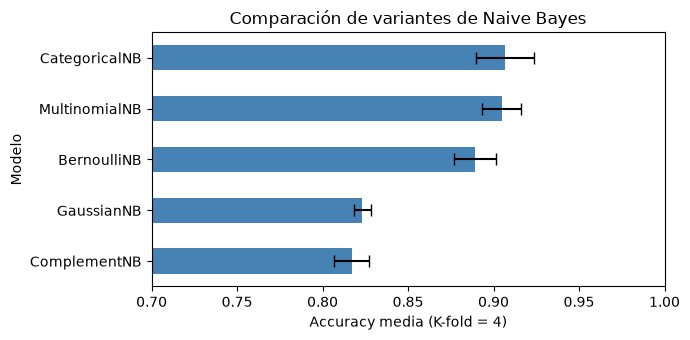

In [8]:
ax = resultados["Accuracy"].plot(kind="barh", xerr=resultados["Acc (std)"],
                                 color="steelblue", figsize=(7, 3.5), capsize=4)
ax.set_xlabel("Accuracy media (K-fold = 4)")
ax.set_xlim(0.7, 1.0)
ax.invert_yaxis()
ax.set_title("Comparación de variantes de Naive Bayes")
plt.tight_layout()
plt.show()

### ¿Qué clasificador escogí? `MultinomialNB`

Analizando la tabla y la gráfica:

- **`GaussianNB`** quedó bastante por debajo (~82 %). Tiene sentido, porque supone datos normales y ya vimos que los nuestros son discretos, acotados y llenos de ceros.
- **`ComplementNB`** también salió bajo. Está pensado para texto con clases desbalanceadas, y aquí las clases están balanceadas.
- **`BernoulliNB`** no salió mal, pero al convertir todo a 0 y 1 **se pierde información**: un bloque con 8 píxeles encendidos y uno con 16 terminan siendo lo mismo.
- **`MultinomialNB`** y **`CategoricalNB`** fueron los mejores y quedaron prácticamente empatados (la diferencia es menor que su desviación estándar).

Al final me quedé con **`MultinomialNB`** por tres razones:
1. **Su supuesto es el que mejor describe los datos:** cada característica es un conteo de píxeles encendidos, y eso es exactamente lo que modela la distribución multinomial. Era lo que esperaba desde la sección 4.
2. **Es más sencillo:** solo estima 64 parámetros por clase ($\theta_{yj}$), mientras que `CategoricalNB` estima $64 \times 17 = 1088$. Con unas 145 imágenes de entrenamiento por clase, a `CategoricalNB` le quedan muchas combinaciones (píxel, valor) sin ver, así que depende más del suavizado. También se nota en que su desviación entre folds fue más alta.
3. **Respeta el orden de los valores:** para `CategoricalNB`, 15 y 16 son categorías tan distintas como 0 y 16. En cambio, para `MultinomialNB` un valor más alto simplemente significa "más tinta", que es lo que de verdad pasa.

## 6. Suavizado de Laplace

En `MultinomialNB` la probabilidad de cada píxel dentro de una clase se calcula así:

$$
\hat{\theta}_{yj} = \frac{N_{yj} + \alpha}{N_y + \alpha\, n}
$$

donde:
- $N_{yj}$ es la suma de los valores del píxel $j$ en todas las imágenes de la clase $y$,
- $N_y = \sum_j N_{yj}$ es el total de "tinta" de la clase $y$,
- $n = 64$ es el número de características,
- $\alpha$ es el parámetro de suavizado.

**¿Para qué sirve?** Si en el entrenamiento un píxel nunca tuvo tinta en ninguna imagen de cierta clase ($N_{yj} = 0$), sin suavizado quedaría $\hat{\theta}_{yj} = 0$. El problema es que, si después llega una imagen de esa clase con aunque sea un poquito de tinta en ese píxel, todo el producto $\prod_j \theta_{yj}^{x_j}$ se vuelve **0** y la clase queda descartada, sin importar qué digan los otros 63 píxeles.

Según el valor de $\alpha$:
- $\alpha = 1$ es el **suavizado de Laplace**: es como si sumara una observación "inventada" a cada píxel.
- $0 < \alpha < 1$ se llama suavizado de Lidstone (más suave).
- $\alpha \to 0$ es no suavizar nada (máxima verosimilitud).

Antes de aplicarlo quise comprobar si este problema de los ceros **de verdad aparece** en estos datos:

In [9]:
conteos_clase = np.array([X_train[y_train == c].sum(axis=0) for c in range(10)])
ceros = (conteos_clase == 0)

print(f"Pares (clase, píxel) con conteo 0: {ceros.sum()} de {ceros.size}")
print("Píxeles con conteo 0 por clase:", dict(zip(range(10), ceros.sum(axis=1).tolist())))

# ¿Cuántas imágenes de prueba tienen tinta en un píxel que su propia clase nunca usó en entrenamiento?
afectadas = sum(np.any((X_test[i] > 0) & ceros[y_test[i]]) for i in range(len(X_test)))
print(f"\nImágenes de prueba afectadas (sin suavizado su clase real tendría P = 0): "
      f"{afectadas} de {len(X_test)}")

Pares (clase, píxel) con conteo 0: 129 de 640
Píxeles con conteo 0 por clase: {0: 16, 1: 14, 2: 9, 3: 10, 4: 11, 5: 13, 6: 16, 7: 15, 8: 14, 9: 11}

Imágenes de prueba afectadas (sin suavizado su clase real tendría P = 0): 5 de 360


Sí aparece: hay 129 combinaciones (clase, píxel) con conteo 0, y 5 imágenes de prueba tienen tinta justo en un píxel que su propia clase nunca usó en el entrenamiento. Sin suavizado, esas imágenes tendrían probabilidad casi 0 de ser clasificadas en su clase real.

### 6.1 Con suavizado de Laplace ($\alpha = 1$) vs. sin suavizado

scikit-learn no deja poner $\alpha = 0$ exactamente, así que para simular "sin suavizado" usé $\alpha = 10^{-10}$.

In [10]:
def evaluar_cv(alpha):
    cv = cross_validate(MultinomialNB(alpha=alpha), X_train, y_train,
                        cv=kfold, scoring=metricas)
    return {m: cv[f"test_{m}"].mean() for m in metricas}

comparacion = pd.DataFrame({
    "Sin suavizado (α≈0)": evaluar_cv(1e-10),
    "Laplace (α=1)":       evaluar_cv(1.0),
}).T
comparacion.columns = ["Accuracy", "Precisión", "Recall", "F1"]
comparacion.round(4)

,Accuracy,Precisión,Recall,F1
Sin suavizado (α≈0),0.9033,0.9110,0.9034,0.9035
Laplace (α=1),0.9047,0.9121,0.9048,0.9050


La mejora con Laplace es pequeña pero existe en las cuatro métricas. Para entender mejor el papel de $\alpha$ hice un barrido más amplio.

### 6.2 Efecto de $\alpha$ en los indicadores de desempeño

Probé valores de $\alpha$ en escala logarítmica, desde $10^{-10}$ hasta $10^{7}$, y para cada uno calculé accuracy, precisión, recall y F1 con K-fold = 4.

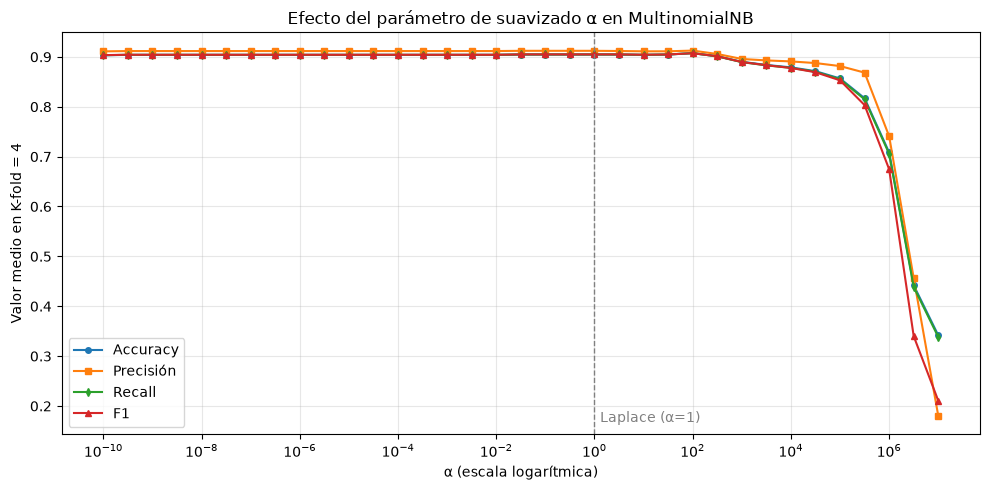

In [11]:
alphas = np.logspace(-10, 7, 35)
curvas = pd.DataFrame([evaluar_cv(a) for a in alphas], index=alphas)
curvas.columns = ["Accuracy", "Precisión", "Recall", "F1"]

fig, ax = plt.subplots(figsize=(10, 5))
for col, marker in zip(curvas.columns, "osd^"):
    ax.plot(curvas.index, curvas[col], marker=marker, markersize=4, label=col)
ax.axvline(1.0, color="gray", ls="--", lw=1)
ax.text(1.3, 0.03, "Laplace (α=1)", color="gray", transform=ax.get_xaxis_transform())
ax.set_xscale("log")
ax.set_xlabel("α (escala logarítmica)")
ax.set_ylabel("Valor medio en K-fold = 4")
ax.set_title("Efecto del parámetro de suavizado α en MultinomialNB")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
# Tabla resumida para algunos valores representativos de alpha
alphas_tabla = [1e-10, 1e-3, 0.1, 1, 10, 100, 1e3, 1e4, 1e5, 1e6, 1e7]
tabla = pd.DataFrame([evaluar_cv(a) for a in alphas_tabla], index=alphas_tabla)
tabla.columns = ["Accuracy", "Precisión", "Recall", "F1"]
tabla.index.name = "α"
tabla.round(4)

,Accuracy,Precisión,Recall,F1
α,,,,
1.000000e-10,0.9033,0.9110,0.9034,0.9035
1.000000e-03,0.9040,0.9117,0.9041,0.9042
1.000000e-01,0.9047,0.9121,0.9048,0.9050
1.000000e+00,0.9047,0.9121,0.9048,0.9050
1.000000e+01,0.9040,0.9111,0.9041,0.9043
1.000000e+02,0.9074,0.9126,0.9075,0.9074
1.000000e+03,0.8901,0.8958,0.8895,0.8897
1.000000e+04,0.8789,0.8909,0.8780,0.8778
1.000000e+05,0.8567,0.8815,0.8552,0.8529


In [13]:
# ¿Qué le pasa a las probabilidades θ cuando alpha crece?
for a in [1e-10, 1, 100, 1e4, 1e6, 1e7]:
    m = MultinomialNB(alpha=a).fit(X_train, y_train)
    theta = np.exp(m.feature_log_prob_)
    print(f"α = {a:>8g} | θ mínima = {theta.min():.2e} | "
          f"diferencia media de θ entre clases = {theta.std(axis=0).mean():.5f}")
print(f"\nDistribución uniforme: θ = 1/64 = {1/64:.5f} para todos los píxeles y clases")

α =    1e-10 | θ mínima = 2.16e-15 | diferencia media de θ entre clases = 0.00731
α =        1 | θ mínima = 2.16e-05 | diferencia media de θ entre clases = 0.00730
α =      100 | θ mínima = 1.90e-03 | diferencia media de θ entre clases = 0.00640
α =    10000 | θ mínima = 1.46e-02 | diferencia media de θ entre clases = 0.00048
α =    1e+06 | θ mínima = 1.56e-02 | diferencia media de θ entre clases = 0.00001
α =    1e+07 | θ mínima = 1.56e-02 | diferencia media de θ entre clases = 0.00000

Distribución uniforme: θ = 1/64 = 0.01562 para todos los píxeles y clases


### ¿Qué efecto tiene $\alpha$?

Con la gráfica y las tablas pude distinguir tres zonas:

1. **$\alpha \to 0$ (sin suavizado):** los píxeles que una clase nunca usó quedan con probabilidad casi cero (la θ mínima fue de ≈ $10^{-15}$). Si una imagen de prueba tiene tinta en uno de esos píxeles, esa clase queda muy castigada. Es una especie de **sobreajuste**: el modelo se cree al pie de la letra lo que vio en el entrenamiento. Las métricas salen un poquito más bajas que con $\alpha = 1$.

2. **$\alpha \approx 1$ (Laplace) y, en general, entre $10^{-3}$ y $10^{2}$:** las métricas se mantienen **estables y en su punto más alto**. Me sorprendió que el cambio fuera tan pequeño, pero tiene explicación: los conteos por clase son grandes (cientos de unidades de tinta por píxel), así que sumarles 1 casi no cambia las probabilidades de los píxeles que sí se usan. Lo único que hace es arreglar los ceros.

3. **$\alpha$ grande ($\gtrsim 10^{3}$):** aquí $\alpha$ empieza a pesar más que los datos reales y todas las $\hat{\theta}_{yj}$ se acercan a $1/64$, o sea, a una distribución **uniforme e igual para todas las clases**. El modelo va perdiendo la capacidad de distinguir los dígitos (**subajuste**) y todas las métricas bajan: accuracy ≈ 0.89 con $\alpha = 10^{3}$, ≈ 0.86 con $10^{5}$, ≈ 0.71 con $10^{6}$ y ≈ 0.34 con $10^{7}$.

   Yo esperaba que el desempeño cayera mucho más rápido, pero tiene lógica que al principio baje despacio: para clasificar solo importa **cuál** clase tiene la probabilidad más alta, no el valor exacto. Mientras queden pequeñas diferencias entre las $\theta_{yj}$ de cada clase, el orden se mantiene en parte. Cuando $\alpha$ es muchísimo más grande que los conteos, esas diferencias desaparecen y el modelo colapsa.

**En resumen:** $\alpha$ controla el equilibrio entre **sesgo y varianza**. Con un $\alpha$ pequeño el modelo confía totalmente en los datos (poco sesgo, mucha varianza), y con uno muy grande "aplana" las probabilidades hacia la uniforme (mucho sesgo). El suavizado de Laplace ($\alpha = 1$) queda en la zona buena: elimina el problema de las probabilidades cero sin borrar lo que el modelo aprendió.

### 6.3 ¿Cuál es el mejor $\alpha$ según K-fold = 4?

Por curiosidad, también busqué cuál $\alpha$ da la mejor accuracy en validación cruzada.

In [14]:
mejor_alpha = curvas["Accuracy"].idxmax()
print(f"Mejor α en validación cruzada: {mejor_alpha:.4g}")
print(f"Accuracy CV con mejor α:       {curvas['Accuracy'].max():.4f}")
print(f"Accuracy CV con Laplace (α=1): {evaluar_cv(1.0)['accuracy']:.4f}")

Mejor α en validación cruzada: 100
Accuracy CV con mejor α:       0.9074
Accuracy CV con Laplace (α=1): 0.9047


El mejor fue $\alpha = 100$, pero la diferencia con $\alpha = 1$ es de apenas unas décimas de punto porcentual, menos que lo que varían los resultados entre folds. Como no es una diferencia significativa y el enunciado pide suavizado de Laplace, decidí que el **modelo final use $\alpha = 1$**.

## 7. Evaluación final con el conjunto de prueba

Ahora sí, entreno `MultinomialNB(alpha=1)` con todo el conjunto de entrenamiento y lo evalúo **una sola vez** con el 20 % de prueba que había dejado aparte.

In [15]:
modelo_final = MultinomialNB(alpha=1.0)
modelo_final.fit(X_train, y_train)
y_pred = modelo_final.predict(X_test)

print("=== MultinomialNB con suavizado de Laplace (α = 1) ===")
print(f"Accuracy:            {accuracy_score(y_test, y_pred):.4f}")
print(f"Precisión (macro):   {precision_score(y_test, y_pred, average='macro'):.4f}")
print(f"Recall (macro):      {recall_score(y_test, y_pred, average='macro'):.4f}")
print(f"F1 (macro):          {f1_score(y_test, y_pred, average='macro'):.4f}")
print()
print(classification_report(y_test, y_pred, digits=3))

=== MultinomialNB con suavizado de Laplace (α = 1) ===
Accuracy:            0.8889
Precisión (macro):   0.8882
Recall (macro):      0.8887
F1 (macro):          0.8871

              precision    recall  f1-score   support

           0      1.000     0.972     0.986        36
           1      0.719     0.639     0.676        36
           2      0.846     0.943     0.892        35
           3      0.973     0.973     0.973        37
           4      0.947     1.000     0.973        36
           5      0.969     0.838     0.899        37
           6      0.971     0.944     0.958        36
           7      0.900     1.000     0.947        36
           8      0.800     0.800     0.800        35
           9      0.757     0.778     0.767        36

    accuracy                          0.889       360
   macro avg      0.888     0.889     0.887       360
weighted avg      0.889     0.889     0.888       360



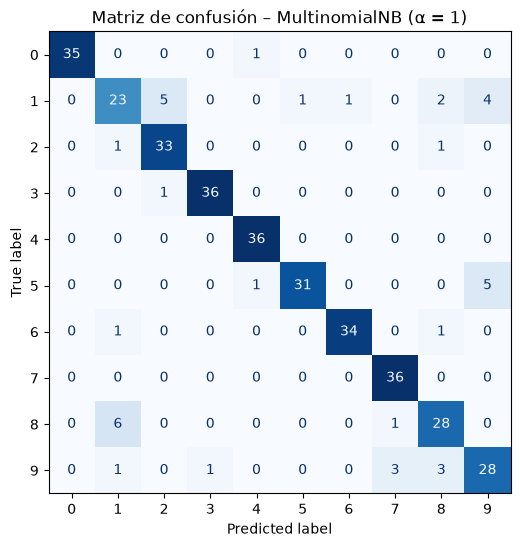

In [16]:
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues", ax=ax, colorbar=False)
ax.set_title("Matriz de confusión – MultinomialNB (α = 1)")
plt.show()

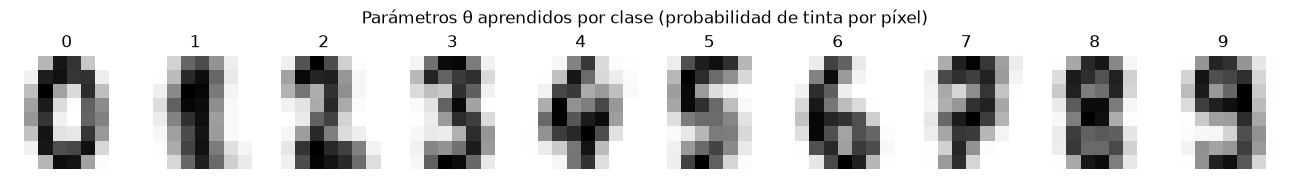

In [17]:
# Lo que "aprendió" el modelo: la distribución θ_yj de cada clase, vista como imagen
theta = np.exp(modelo_final.feature_log_prob_)
fig, axes = plt.subplots(1, 10, figsize=(13, 1.8))
for c, ax in enumerate(axes):
    ax.imshow(theta[c].reshape(8, 8), cmap="gray_r")
    ax.set_title(c)
    ax.axis("off")
plt.suptitle("Parámetros θ aprendidos por clase (probabilidad de tinta por píxel)")
plt.tight_layout()
plt.show()

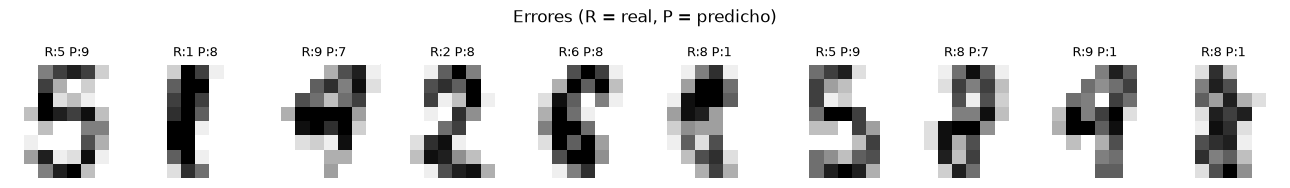

In [18]:
# Algunos errores del modelo
errores = np.where(y_pred != y_test)[0][:10]
fig, axes = plt.subplots(1, len(errores), figsize=(1.3 * len(errores), 2))
for ax, i in zip(np.atleast_1d(axes), errores):
    ax.imshow(X_test[i].reshape(8, 8), cmap="gray_r")
    ax.set_title(f"R:{y_test[i]} P:{y_pred[i]}", fontsize=9)
    ax.axis("off")
plt.suptitle("Errores (R = real, P = predicho)")
plt.tight_layout()
plt.show()

## 8. Conclusiones

1. **Distribución de los datos:** las 64 características del dataset *digits* son **conteos enteros de 0 a 16** (píxeles encendidos en bloques de 4×4), con casi la mitad de los valores en 0. No son continuos ni normales, así que el modelo que mejor los describe es el **multinomial**.
2. **Clasificador escogido:** `MultinomialNB`. En la validación cruzada con K-fold = 4 le ganó claramente a `GaussianNB`, `BernoulliNB` y `ComplementNB`, y empató con `CategoricalNB`, que es mucho más complejo (17 veces más parámetros) y no aprovecha el orden de los valores.
3. **Suavizado de Laplace:** sí es necesario, porque hay combinaciones (clase, píxel) con conteo 0 que sin suavizado harían que algunas imágenes de prueba tuvieran probabilidad cero en su clase real.
4. **Efecto de $\alpha$:**
   - $\alpha \to 0$: un poco de sobreajuste por las probabilidades cero.
   - Entre $10^{-3}$ y $10^{2}$ (incluido Laplace, $\alpha = 1$): el mejor desempeño y bastante estable.
   - $\alpha \gtrsim 10^{3}$: las probabilidades tienden a la uniforme, el modelo pierde poder para distinguir clases y todas las métricas caen (accuracy ≈ 0.71 con $\alpha = 10^{6}$ y ≈ 0.34 con $10^{7}$).
5. **Resultado final:** `MultinomialNB(alpha=1)` logró alrededor de **89 % de accuracy** en el conjunto de prueba y ~90 % en validación cruzada. Como los dos valores son parecidos, el modelo generaliza bien. Las clases que más le costaron fueron **1, 9 y 8** (F1 ≈ 0.68, 0.77 y 0.80), que son dígitos con trazos parecidos. Creo que esto pasa por el supuesto de independencia de Naive Bayes: el modelo mira cada píxel por separado y no tiene en cuenta la forma que hacen los píxeles vecinos juntos.

En general, este trabajo me ayudó a ver que escoger la distribución correcta según la naturaleza de los datos importa más que ajustar hiperparámetros: pasar de `GaussianNB` a `MultinomialNB` mejoró la accuracy en ~8 puntos, mientras que mover $\alpha$ dentro de un rango razonable casi no la cambió.